In [13]:
import sys, os
sys.path.append(os.path.abspath('..'))

import joblib
import shap
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from src.preprocessing import get_preprocessor
import lime
import lime.lime_tabular
import numpy as np

In [14]:
df = pd.read_csv('../data/WA_Fn-UseC_-Telco-Customer-Churn.csv')
df.drop('customerID', axis=1, inplace=True)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')


X = df.drop('Churn', axis=1)
encoder_target = LabelEncoder()
y = encoder_target.fit_transform(df['Churn'])


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)



C:\Users\roky\AppData\Local\Temp\ipykernel_10572\1169100114.py:2: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop('customerID', axis=1, inplace=True)


In [15]:
xgb_pipeline = joblib.load('../models/xgboost_pipeline.joblib')

In [16]:
preprocessor = xgb_pipeline.named_steps['preprocessor']
xgb_model = xgb_pipeline.named_steps['classifier']

In [17]:
X_test_transformed = preprocessor.transform(X_test)
feature_names = [
    name.split('__')[-1] 
    for name in preprocessor.get_feature_names_out()
]

In [18]:
X_test_df = pd.DataFrame(X_test_transformed, columns=feature_names)

In [19]:
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_test_df)

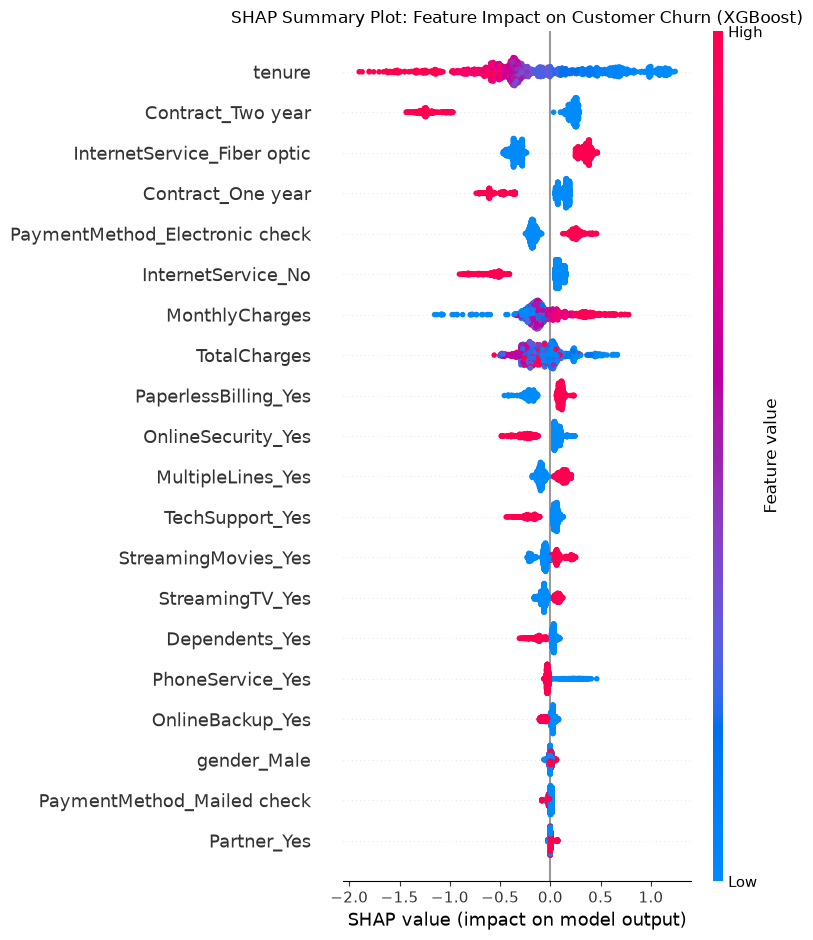

In [20]:
plt.figure(figsize=(10, 7))
shap.summary_plot(shap_values, X_test_df, show=False)
plt.title("SHAP Summary Plot: Feature Impact on Customer Churn (XGBoost)")
plt.tight_layout()
plt.show()

In [22]:
X_train_transformed = preprocessor.transform(X_train)

In [23]:
lime_explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=X_train_transformed,
    feature_names=feature_names,
    class_names=['No Churn (0)', 'Churn (1)'],
    mode='classification',
    random_state=42
)

In [24]:
sample_idx = 0  
customer_instance = X_test_transformed[sample_idx]

In [26]:
exp = lime_explainer.explain_instance(
    data_row=customer_instance,
    predict_fn=xgb_model.predict_proba,
    num_features=10
)

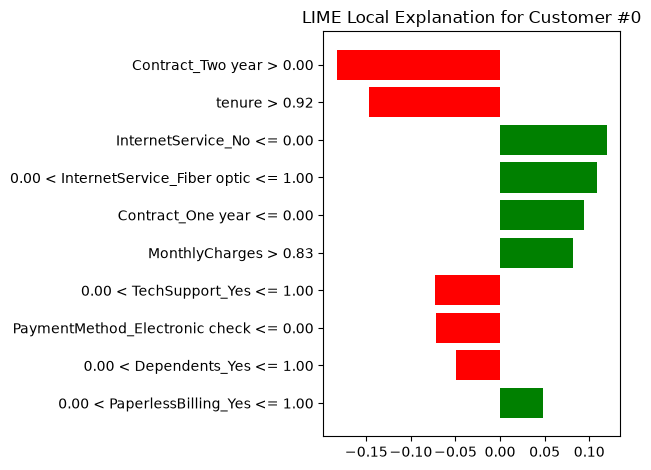

In [27]:
fig = exp.as_pyplot_figure()
plt.title(f"LIME Local Explanation for Customer #{sample_idx}")
plt.tight_layout()
plt.show()